# Hessian flow matching on the simplex

This notebook trains a categorical generative model with **Hessian flow matching** (`HessianProbPath`). A convex
potential $\phi$ (Bregman generator) defines the whole method:

- **path**: endpoints are interpolated linearly in dual coordinates $\gamma = \nabla\phi(x)$ and mapped back to the simplex by the constrained Legendre map, $x_t = x\big((1-t)\nabla\phi(x_0) + t\nabla\phi(x_1)\big)$;
- **loss**: the velocity is regressed in the Hessian metric, $\|v_\theta(x_t, t) - \dot x_t\|^2_{\nabla^2\phi(x_t)}$, written inline with `potential.metric`;
- **parametrization**: the network outputs a raw $r_\theta$ that the potential maps to a tangent velocity, $v = x \odot (r - \langle x, r\rangle\mathbf{1})$ (`potential.tangent_from_output`).

We compare negative entropy, $\phi(x) = \sum_k x_k\log x_k$ (e-geodesic paths), with a **kernel-smoothed entropy**
$\phi(x) = \lambda_0\, x^\top\log x + \lambda_1 (Mx)^\top\log(Mx)$, where the substitution kernel $M$ makes categories 0 and 1 interchangeable.

## Imports and init device

In [1]:
import time

import matplotlib.pyplot as plt
import torch
from torch import nn, Tensor
from torch.distributions import Dirichlet

# flow_matching
from flow_matching.path import DirichletSmoothing, HessianProbPath
from flow_matching.path.potential import KernelSmoothedEntropy, NegativeEntropy
from flow_matching.path.scheduler import CondOTScheduler
from flow_matching.solver import ODESolver
from flow_matching.utils import ModelWrapper, project_interior

In [2]:
if torch.cuda.is_available():
    device = "cuda:0"
    print("Using gpu")
else:
    device = "cpu"
    print("Using cpu.")
torch.manual_seed(42)

Using cpu.


## Dataset

Sequences of $L = 2$ sites over $K = 3$ categories, drawn from a joint distribution with strong dependence between the sites.
Each category is a vertex $e_k$ of the simplex. One-hot data are mapped into the simplex interior by a label
smoothing (`DirichletSmoothing`): $x_1 = \nu e_k + (1-\nu)[\tau\mathbf{1} + (1-K\tau)\zeta]$, $\zeta \sim \mathrm{Dir}(\alpha)$.

In [3]:
K, L = 3, 2
joint = torch.tensor(
    [
        [0.30, 0.05, 0.00],
        [0.05, 0.25, 0.05],
        [0.00, 0.05, 0.25],
    ]
)


def sample_labels(batch_size: int, device: str = "cpu") -> Tensor:
    index = torch.multinomial(joint.flatten(), batch_size, replacement=True)
    sites = torch.stack([index // K, index % K], dim=-1)
    return nn.functional.one_hot(sites, K).float().to(device)


smoothing = DirichletSmoothing()  # nu = 0.9, alpha = 100, K tau = 0.2 (paper, App. H.1)


def sample_source(batch_size: int, device: str = "cpu") -> Tensor:
    # Uniform Dirichlet source, clipped away from the boundary (paper, App. I.3).
    return project_interior(Dirichlet(torch.ones(K)).sample((batch_size, L))).to(device)

## Potentials

The substitution kernel is a lazy random walk $M = (1-\alpha)I + \alpha P$ on an affinity graph in which categories 0 and 1 are close.

In [4]:
affinity = torch.tensor([[0.0, 1.0, 0.1], [1.0, 0.0, 0.1], [0.1, 0.1, 0.0]])
jump = affinity / affinity.sum(dim=0, keepdim=True)  # column-stochastic substitution kernel P
lazy = 0.5 * torch.eye(K) + 0.5 * jump  # M = (1 - alpha) I + alpha P, alpha = 1/2

potentials = {
    "negative entropy": NegativeEntropy(),
    "kernel-smoothed entropy": KernelSmoothedEntropy(kernels=lazy[None], lambdas=torch.tensor([0.9])),
}
paths = {
    name: HessianProbPath(scheduler=CondOTScheduler(), potential=potential)
    for name, potential in potentials.items()
}

### Conditional paths

Both paths join the same endpoints. The smoothed geometry makes moving mass between the substitutable categories 0 and 1 cheaper, which bends the path.

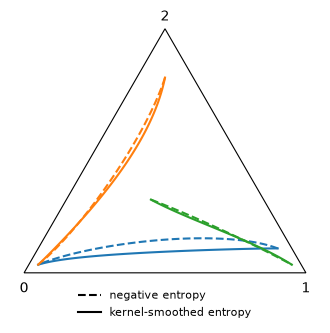

In [5]:
def to_plane(x: Tensor) -> Tensor:
    # Barycentric coordinates -> 2D coordinates of the equilateral triangle.
    return torch.stack([x[..., 1] + 0.5 * x[..., 2], (3**0.5 / 2) * x[..., 2]], dim=-1)


def draw_triangle(ax):
    corners = to_plane(torch.eye(K))
    ax.fill(corners[:, 0], corners[:, 1], facecolor="none", edgecolor="black", linewidth=0.8)
    for k, (cx, cy) in enumerate(corners.tolist()):
        ax.annotate(f"{k}", (cx, cy), textcoords="offset points", xytext=(0, 6 if k == 2 else -14), ha="center")
    ax.set_aspect("equal")
    ax.axis("off")


x_0 = torch.tensor([[0.05, 0.85, 0.10], [0.10, 0.10, 0.80], [0.40, 0.30, 0.30]])
x_1 = smoothing(torch.eye(K)[[0, 0, 1]], stochastic=False)
t = torch.linspace(0, 1, 101)

fig, ax = plt.subplots(figsize=(4, 4))
draw_triangle(ax)
for (name, path), style in zip(paths.items(), ["--", "-"]):
    for i in range(len(x_0)):
        x_t = path.sample(x_0=x_0[i].expand(len(t), K), x_1=x_1[i].expand(len(t), K), t=t).x_t
        ax.plot(*to_plane(x_t).T, style, color=f"C{i}")
handles = [plt.Line2D([], [], color="black", linestyle=style) for style in ["--", "-"]]
ax.legend(handles, list(paths), loc="upper center", bbox_to_anchor=(0.5, 0.02), fontsize=8, frameon=False)
plt.show()

## Model

In [6]:
class MLP(nn.Module):
    def __init__(self, num_sites: int, num_classes: int, hidden_dim: int = 128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(num_sites * num_classes + 1, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, num_sites * num_classes),
        )

    def forward(self, x: Tensor, t: Tensor) -> Tensor:
        # Reads the whole sequence, so it can learn interactions between sites. Returns a raw output r.
        t = t.reshape(-1, 1).expand(x.shape[0], 1)
        h = torch.cat([x.flatten(start_dim=1), t], dim=-1)
        return self.net(h).reshape(x.shape)


class HessianHead(ModelWrapper):
    # Output head (paper, App. I.2): maps the raw output r to a tangent velocity on the simplex.
    def __init__(self, model: nn.Module, potential: nn.Module):
        super().__init__(model)
        self.potential = potential

    def forward(self, x: Tensor, t: Tensor, **extras) -> Tensor:
        return self.potential.tangent_from_output(x, self.model(x=x, t=t, **extras))

## Train

`path.sample` returns $x_t$ and $\dot x_t$; for the kernel-smoothed entropy, $x_t$ is computed by Newton's method in double precision.

In [7]:
lr = 1e-3
batch_size = 1024
iterations = 3001
print_every = 1000

models = {}
for name, path in paths.items():
    model = HessianHead(MLP(L, K).to(device), path.potential)  # raw output r -> tangent velocity
    optim = torch.optim.Adam(model.parameters(), lr=lr)

    start_time = time.time()
    for i in range(iterations):
        optim.zero_grad()
        x_1 = smoothing(sample_labels(batch_size, device))
        x_0 = sample_source(batch_size, device)
        t = torch.rand(batch_size, device=device)
        path_sample = path.sample(x_0=x_0, x_1=x_1, t=t)

        # Hessian-metric regression: sum over sites, mean over the batch.
        diff = model(path_sample.x_t, path_sample.t) - path_sample.dx_t
        loss = path.potential.metric(path_sample.x_t, diff, diff).sum(dim=-1).mean()
        loss.backward()
        optim.step()

        if i % print_every == 0:
            elapsed = time.time() - start_time
            print(f"[{name}] iter {i:5d} | {elapsed * 1000 / print_every:6.2f} ms/step | loss {loss.item():8.4f}")
            start_time = time.time()
    models[name] = model

[negative entropy] iter     0 |   0.01 ms/step | loss   5.3430


[negative entropy] iter  1000 |   1.56 ms/step | loss   2.4077


[negative entropy] iter  2000 |   1.60 ms/step | loss   2.2556


[negative entropy] iter  3000 |   1.43 ms/step | loss   2.2447
[kernel-smoothed entropy] iter     0 |   0.01 ms/step | loss   1.1101


[kernel-smoothed entropy] iter  1000 |   6.29 ms/step | loss   0.4802


[kernel-smoothed entropy] iter  2000 |   6.25 ms/step | loss   0.4109


[kernel-smoothed entropy] iter  3000 |   6.42 ms/step | loss   0.3883


## Sample

The velocity is tangent to the simplex everywhere, so we integrate it with the Euclidean `ODESolver`; no Legendre map is needed at inference.
Samples are decoded to categories by argmax.

In [8]:
num_samples = 20000
time_grid = torch.linspace(0, 1, 6, device=device)
samples = {}
for name, model in models.items():
    solver = ODESolver(velocity_model=model)
    with torch.no_grad():
        samples[name] = solver.sample(
            x_init=sample_source(num_samples, device),
            step_size=0.01,
            method="midpoint",
            time_grid=time_grid,
            return_intermediates=True,
        ).cpu()


def empirical_joint(x: Tensor) -> Tensor:
    sites = x.argmax(dim=-1)
    counts = torch.bincount(sites[:, 0] * K + sites[:, 1], minlength=K * K).float()
    return (counts / counts.sum()).reshape(K, K)


for name, sol in samples.items():
    estimate = empirical_joint(sol[-1])
    print(f"[{name}] total variation to the data distribution: {0.5 * (estimate - joint).abs().sum():.4f}")

[negative entropy] total variation to the data distribution: 0.0144
[kernel-smoothed entropy] total variation to the data distribution: 0.0265


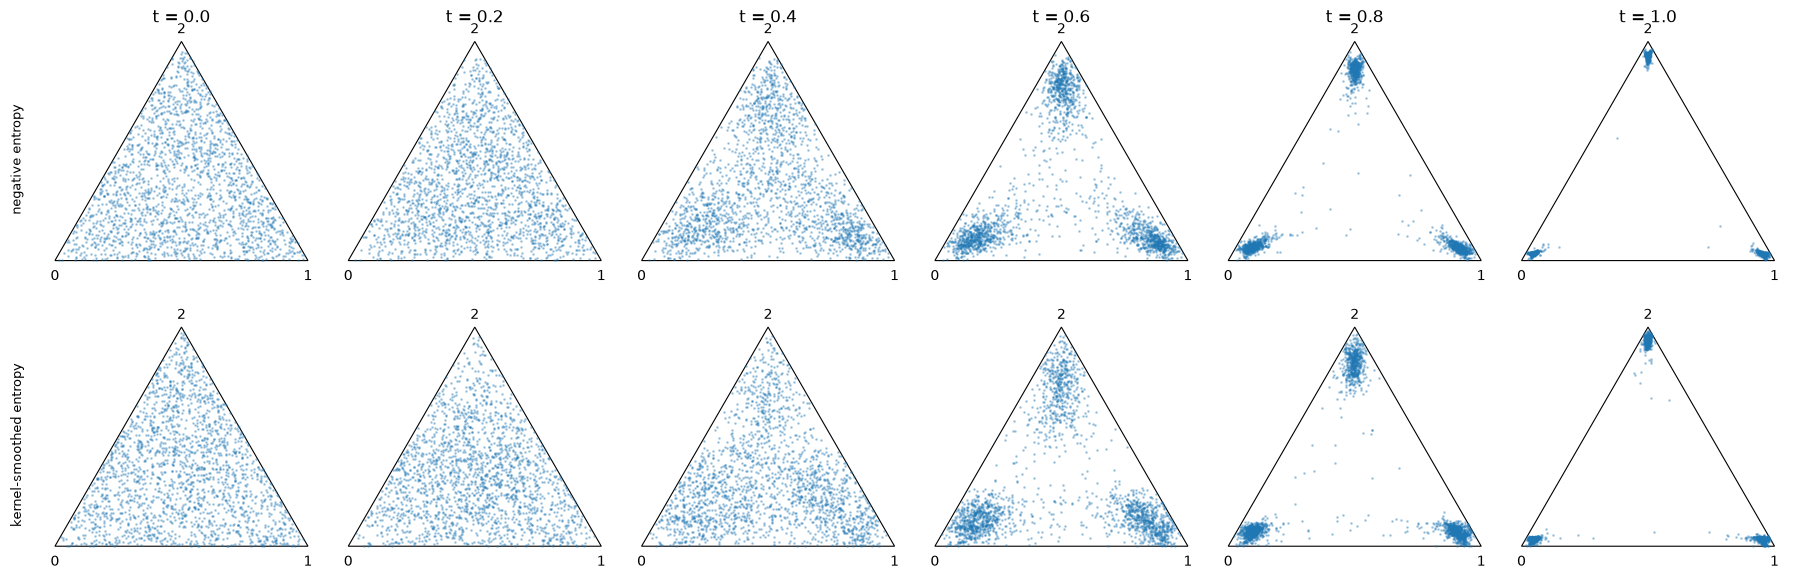

In [9]:
fig, axs = plt.subplots(len(samples), len(time_grid), figsize=(3 * len(time_grid), 3 * len(samples)))
for row, (name, sol) in enumerate(samples.items()):
    for col, t in enumerate(time_grid.tolist()):
        ax = axs[row, col]
        draw_triangle(ax)
        ax.scatter(*to_plane(sol[col, :2000, 0]).T, s=1, alpha=0.3, color="C0")
        ax.set_title(f"t = {t:.1f}" if row == 0 else "")
    axs[row, 0].text(-0.15, 0.4, name, rotation=90, ha="center", va="center", fontsize=9)
plt.tight_layout()
plt.show()

### Projected Euler sampler

The hessian-flow reference implementation integrates with explicit Euler steps followed by a projection onto the simplex
interior (clipping at $10^{-4}$). This is reproduced with `RiemannianODESolver` and a minimal `Manifold`. The projection
is a numerical safeguard: it changes the density, so it is not used for likelihoods.

In [10]:
from flow_matching.solver import RiemannianODESolver
from flow_matching.utils.manifolds import Manifold


class InteriorSimplex(Manifold):
    def expmap(self, x: Tensor, u: Tensor) -> Tensor:
        return x + u

    def logmap(self, x: Tensor, y: Tensor) -> Tensor:
        return y - x

    def projx(self, x: Tensor) -> Tensor:
        return project_interior(x, eps=1e-4)

    def proju(self, x: Tensor, u: Tensor) -> Tensor:
        return u  # the velocity model is already tangent


for name, model in models.items():
    solver = RiemannianODESolver(manifold=InteriorSimplex(), velocity_model=model)
    with torch.no_grad():
        x = solver.sample(x_init=sample_source(num_samples, device), step_size=0.01, method="euler").cpu()
    print(f"[{name}] projected Euler, total variation: {0.5 * (empirical_joint(x) - joint).abs().sum():.4f}")

[negative entropy] projected Euler, total variation: 0.0172


[kernel-smoothed entropy] projected Euler, total variation: 0.0299


## Likelihood

Because the velocity satisfies $\mathbf{1}^\top v(x) = 0$ for every $x$, the Euclidean divergence equals the intrinsic divergence on the
simplex, so `ODESolver.compute_likelihood` applies unchanged.
We evaluate the continuous log-density $\log q_\theta(x_1)$ of smoothed data, with the uniform Dirichlet source density.

In [11]:
def log_p0(x: Tensor) -> Tensor:
    return Dirichlet(torch.ones(K, device=x.device)).log_prob(x).sum(dim=-1)


x_1 = smoothing(sample_labels(2000, device))
for name, model in models.items():
    solver = ODESolver(velocity_model=model)
    _, log_q = solver.compute_likelihood(
        x_1=x_1, log_p0=log_p0, step_size=0.01, method="midpoint", exact_divergence=True
    )
    print(f"[{name}] mean log-density of smoothed data: {log_q.mean().item():.3f}")

[negative entropy] mean log-density of smoothed data: 15.054


[kernel-smoothed entropy] mean log-density of smoothed data: 13.627
